In [17]:
import sys
sys.path.append(r"D:\Book Store\M.Tech\M.Tech Thesis\Truss Topology Optimisation")

import numpy as np
from math import comb
import matplotlib.pyplot as plt
from src.ground_structure import generate_ground_structure, connectivity_to_state, state_to_connectivity, state_to_index, index_to_state, cal_vol
from src.valid_and_stable import plot_truss, check_stability, get_displacements, get_K

import gymnasium as gym
from gymnasium import spaces

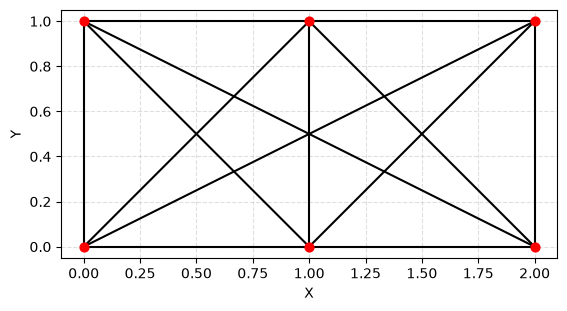

In [18]:
grid = (2, 1)

nodes, ground_structure_bars = generate_ground_structure(grid, plot=True)

In [19]:
nodes, ground_structure_bars

(array([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.],
        [2., 0.],
        [2., 1.]]),
 array([[0, 1],
        [0, 2],
        [0, 3],
        [0, 5],
        [1, 2],
        [1, 3],
        [1, 4],
        [2, 3],
        [2, 4],
        [2, 5],
        [3, 4],
        [3, 5],
        [4, 5]]))

In [20]:
E = 2.1e11  # N/m2
A = 40 # cm2
fixed = np.array([0, 1, 2, 3])
dofs = np.array([i for i in range(2*len(nodes)) if i not in fixed])



In [21]:
dofs

array([ 4,  5,  6,  7,  8,  9, 10, 11])

In [22]:
print(f"Number of Nodes: {len(nodes)}")
print(f"Number of Bars: {len(ground_structure_bars)}")

Number of Nodes: 6
Number of Bars: 13


In [23]:
f0 = 1e5  # N
ff = np.zeros((2*len(nodes), 1))
# ff[13] = -f0
ff[7] = -f0
f = ff[dofs]

In [24]:
check_stability(nodes, ground_structure_bars, dofs, A, E, ff)

True

In [25]:
get_displacements(nodes, ground_structure_bars, A, E, ff, dofs, disp_at=9)  # mm

-0.25667080994005465

In [26]:
ground_state = connectivity_to_state(ground_structure_bars, nodes)
print(ground_state)


[1 1 1 0 1 1 1 1 0 1 1 1 1 1 1]


In [27]:
cal_vol(nodes, ground_state, A)

np.float64(0.06851596081796786)

In [28]:
# gs = np.array([1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0 , 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1])
# gs[17] = 0
# cal_vol(nodes, gs, A)

In [29]:
state_to_index(np.array([0, 1, 0, 1, 1, 1,]))

23

In [35]:
# ============================================================================================
# RL truss topology optimisation by MEMBER REMOVAL
# Q-learning set-up follows Yusuf (2023), Ch. 3: tabular Q-learning, gamma = 1, epsilon and alpha
# decayed with a cosine, Q-table that grows as new states are met, reward = improvement in the
# design objective.  Here the action removes one member of the ground structure, and the
# objective is: minimum volume  s.t.  |u(disp_dof)| <= u_lim  and a stable truss.
# ============================================================================================

disp_dof = 9      # dof whose displacement is checked (node 4, y-direction)
u_lim    = 0.5    # mm  <-- displacement limit, change this


class TrussRemovalEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, nodes, bars, dofs, A, E, ff, disp_dof, u_lim, penalty=0.1, render_mode=None):
        super().__init__()

        self.nodes = nodes.astype(float)
        self.bars = bars.astype(int)           # ground structure, member id = row index (M0, M1, ...)
        self.dofs = np.asarray(dofs).astype(int)
        self.A = A
        self.E = E
        self.ff = ff
        self.disp_dof = disp_dof
        self.u_lim = u_lim
        self.penalty = penalty
        self.n_bars = len(self.bars)

        # Action = which member to remove, state = 0/1 for every member of the ground structure
        self.action_space = spaces.Discrete(self.n_bars)
        self.observation_space = spaces.MultiBinary(self.n_bars)

        L = np.linalg.norm(self.nodes[self.bars[:, 1]] - self.nodes[self.bars[:, 0]], axis=1)
        self.bar_vol = self.A * 1e-4 * L       # m3 of each member
        self.V0 = self.bar_vol.sum()

        # Nodes that must stay in the truss: loaded nodes and the node of disp_dof
        loaded = np.where(np.abs(self.ff[:, 0]) > 0)[0] // 2
        self.keep_nodes = set(loaded.tolist()) | {self.disp_dof // 2}
        # Fully free nodes (no support) - a member hanging from one of these is useless
        self.free_nodes = {k for k in range(len(self.nodes)) if 2*k in self.dofs and 2*k + 1 in self.dofs}

        self.cache = {}                        # FE result of every configuration already analysed
        self.render_mode = render_mode
        self.state = None

    def analyse(self, state):
        key = state.tobytes()
        if key not in self.cache:
            bars = self.bars[state == 1]
            active_nodes = set(bars.ravel().tolist())
            stable, u = False, np.nan
            if self.keep_nodes <= active_nodes:
                # Only the dofs of nodes that still carry members, so a node can drop out of the design
                dofs = np.array([d for d in self.dofs if d // 2 in active_nodes])
                stable = check_stability(self.nodes, bars, dofs, self.A, self.E, self.ff)
                if stable:
                    u = get_displacements(self.nodes, bars, self.A, self.E, self.ff, dofs, disp_at=self.disp_dof)
            self.cache[key] = (stable, u)
        return self.cache[key]

    def remove_dangling(self, state):
        # A free, unloaded node left with a single member is removed together with that member,
        # so a node can leave the design in one step (otherwise it is unstable on the way)
        pruned = []
        while True:
            bars = self.bars[state == 1]
            deg = np.bincount(bars.ravel(), minlength=len(self.nodes))
            dangling = [k for k in self.free_nodes - self.keep_nodes if deg[k] == 1]
            if not dangling:
                return state, pruned
            for k in dangling:
                m = np.where((state == 1) & ((self.bars[:, 0] == k) | (self.bars[:, 1] == k)))[0]
                state[m] = 0
                pruned += m.tolist()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.state = np.ones(self.n_bars, dtype=int)
        return self.state.copy(), {}

    def step(self, action):
        new_state = self.state.copy()
        new_state[action] = 0
        new_state, pruned = self.remove_dangling(new_state)
        stable, u = self.analyse(new_state)
        info = {"u": u, "stable": stable, "pruned": pruned}

        if not stable or abs(u) > self.u_lim:
            # Constraint violated: the removal is rejected, the design stays as it was, episode ends
            return self.state.copy(), -self.penalty, True, False, info

        removed = self.state - new_state
        reward = self.bar_vol[removed == 1].sum() / self.V0      # fraction of the ground-structure volume saved
        self.state = new_state
        return self.state.copy(), reward, False, False, info

    def render(self):
        if self.render_mode == "human":
            plot_truss(self.nodes, self.bars[self.state == 1], show_member_ids=False)

In [36]:
def cosine_decay(m, C, B, floor):
    # eps_m = C cos(B m) as in the thesis, held at `floor` once it gets there
    return max(floor, C * np.cos(B * m)) if B * m < np.pi / 2 else floor


def train_TRE(env, episodes=3000, gamma=1.0, decay_frac=0.7, print_every=500, seed=None):
    rng = np.random.default_rng(seed)

    # B chosen so that epsilon (0.9 -> 0.01) and alpha (1 -> 0.1) reach their floors after decay_frac*episodes
    B_eps = np.arccos(0.01 / 0.9) / (decay_frac * episodes)
    B_alpha = np.arccos(0.1 / 1.0) / (decay_frac * episodes)

    Q = {}                                    # Q-table grows with the states visited
    rewards = []

    for m in range(episodes):
        epsilon = cosine_decay(m, 0.9, B_eps, 0.01)
        alpha = cosine_decay(m, 1.0, B_alpha, 0.1)

        state, _ = env.reset()
        terminated = False
        truncated = False
        total_reward = 0

        while not terminated and not truncated:
            q = Q.setdefault(state.tobytes(), np.zeros(env.n_bars))
            valid = np.where(state == 1)[0]   # only members still present can be removed

            if rng.random() < epsilon:
                action = rng.choice(valid)
            else:
                action = rng.choice(valid[q[valid] == q[valid].max()])

            next_state, reward, terminated, truncated, _ = env.step(action)

            if terminated:
                target = reward
            else:
                q_next = Q.setdefault(next_state.tobytes(), np.zeros(env.n_bars))
                target = reward + gamma * q_next[next_state == 1].max()
            q[action] += alpha * (target - q[action])

            state = next_state
            total_reward += reward

        rewards.append(total_reward)
        if (m + 1) % print_every == 0:
            print(f"Episode: {m+1}, epsilon = {epsilon:.3f}, alpha = {alpha:.3f}, "
                  f"reward = {total_reward:.4f}, configurations analysed = {len(env.cache)}")

    env.close()
    return Q, rewards

In [37]:
def run_trained_TRE_agent(env, Q, plot=True):
    state, _ = env.reset()
    _, u = env.analyse(state)
    history = [{"step": 0, "member": None, "u": u, "V": env.V0, "state": state.copy()}]

    print(f"Displacement limit |u({env.disp_dof})| <= {env.u_lim} mm\n")
    if abs(u) > env.u_lim:
        print(f"WARNING: the full ground structure already has |u| = {abs(u):.4f} mm > limit, "
              f"so no member can be removed. Increase u_lim.\n")
    print(f"{'Step':>4} | {'Removed':>8} | {'Nodes':>8} | {'u at dof ' + str(env.disp_dof) + ' (mm)':>18} | {'Volume (m3)':>11}")
    print("-" * 62)
    print(f"{0:>4} | {'-':>8} | {'-':>8} | {u:>18.4f} | {env.V0:>11.5f}")

    while True:
        valid = np.where(state == 1)[0]
        q = Q.get(state.tobytes(), np.zeros(env.n_bars))
        action = valid[np.argmax(q[valid])]
        next_state, reward, terminated, truncated, info = env.step(action)

        if terminated:                        # best remaining removal breaks a constraint -> stop
            i, j = env.bars[action]
            why = "unstable" if not info["stable"] else f"|u| = {abs(info['u']):.4f} mm > {env.u_lim} mm"
            print(f"\nStop: removing M{action} (N{i}-N{j}) next would give {why}")
            break

        state = next_state
        i, j = env.bars[action]
        V = env.bar_vol[state == 1].sum()
        history.append({"step": len(history), "member": action, "pruned": info["pruned"],
                        "u": info["u"], "V": V, "state": state.copy()})
        extra = f"   (+ dangling {', '.join('M' + str(k) for k in info['pruned'])})" if info["pruned"] else ""
        print(f"{len(history)-1:>4} | {'M' + str(action):>8} | {f'N{i}-N{j}':>8} | {info['u']:>18.4f} | {V:>11.5f}{extra}")

    print(f"\nFinal: {int(state.sum())} of {env.n_bars} members, "
          f"volume {history[-1]['V']:.5f} m3 ({100 * history[-1]['V'] / env.V0:.1f}% of ground structure)")

    if plot:
        # Design after every removal: remaining members in black, the member just removed dashed red
        n = len(history)
        cols = min(n, 4)
        rows = int(np.ceil(n / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
        for ax, h in zip(axes.ravel(), history):
            plot_truss(env.nodes, env.bars[h["state"] == 1], ax=ax, show_member_ids=(h["step"] == 0),
                       show_node_ids=(h["step"] == 0), fontsize=7)
            if h["member"] is None:
                ax.set_title(f"Ground structure\nu = {h['u']:.4f} mm", fontsize=9)
            else:
                for k in [h["member"]] + h["pruned"]:
                    i, j = env.bars[k]
                    ax.plot(env.nodes[[i, j], 0], env.nodes[[i, j], 1], "r--", lw=1.5)
                i, j = env.bars[h["member"]]
                ax.set_title(f"Step {h['step']}: removed M{h['member']} (N{i}-N{j})\nu = {h['u']:.4f} mm", fontsize=9)
        for ax in axes.ravel()[n:]:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        # Displacement of the chosen dof after each removal, with the limit
        fig, ax = plt.subplots(figsize=(6, 3.5))
        steps = [h["step"] for h in history]
        ax.plot(steps, [abs(h["u"]) for h in history], "o-k")
        ax.axhline(env.u_lim, color="r", ls="--", label=f"limit = {env.u_lim} mm")
        ax.set_xticks(steps)
        ax.set_xticklabels(["GS"] + [f"-M{h['member']}" for h in history[1:]], rotation=45)
        ax.set_ylabel(f"|u| at dof {env.disp_dof} (mm)")
        ax.set_xlabel("Member removed")
        ax.legend()
        plt.tight_layout()
        plt.show()

    return history

In [38]:
# Optional check (only for small ground structures, n_bars <= ~16): exhaustive search over every
# subset of members, as in Sec. 4.4 of the thesis.  RL only reaches designs through a sequence of
# feasible removals, so it can match this but not beat it.
def exhaustive_best(env):
    best_V, best_state = np.inf, None
    for idx in range(1, 2**env.n_bars):
        state = index_to_state(idx, env.n_bars)
        V = env.bar_vol[state == 1].sum()
        if V >= best_V:
            continue
        stable, u = env.analyse(state)
        if stable and abs(u) <= env.u_lim:
            best_V, best_state = V, state
    return best_V, best_state

Episode: 500, epsilon = 0.839, alpha = 0.940, reward = -0.1000, configurations analysed = 525
Episode: 1000, epsilon = 0.663, alpha = 0.765, reward = 0.0889, configurations analysed = 843
Episode: 1500, epsilon = 0.398, alpha = 0.498, reward = 0.4534, configurations analysed = 1004
Episode: 2000, epsilon = 0.077, alpha = 0.170, reward = 0.4534, configurations analysed = 1092
Episode: 2500, epsilon = 0.010, alpha = 0.100, reward = 0.4534, configurations analysed = 1102
Episode: 3000, epsilon = 0.010, alpha = 0.100, reward = 0.4292, configurations analysed = 1104


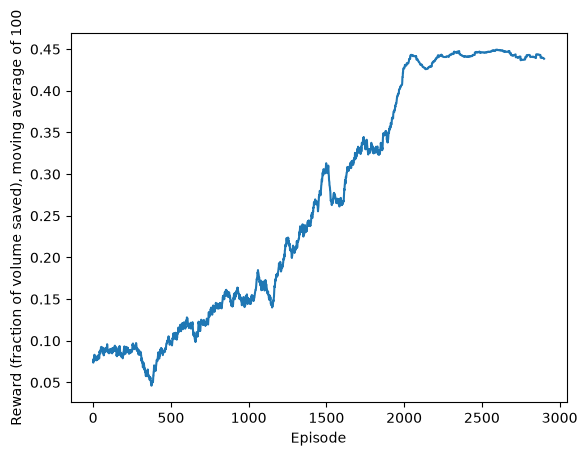

Displacement limit |u(9)| <= 0.5 mm

Step |  Removed |    Nodes |    u at dof 9 (mm) | Volume (m3)
--------------------------------------------------------------
   0 |        - |        - |            -0.2567 |     0.06852
   1 |       M3 |    N0-N5 |            -0.2946 |     0.05957
   2 |      M12 |    N4-N5 |            -0.3013 |     0.05557
   3 |       M9 |    N2-N5 |            -0.3013 |     0.04591   (+ dangling M11)
   4 |       M7 |    N2-N3 |            -0.3821 |     0.04191
   5 |       M0 |    N0-N1 |            -0.3821 |     0.03791
   6 |      M10 |    N3-N4 |             0.0000 |     0.03226

Stop: removing M6 (N1-N4) next would give unstable

Final: 6 of 13 members, volume 0.03226 m3 (47.1% of ground structure)


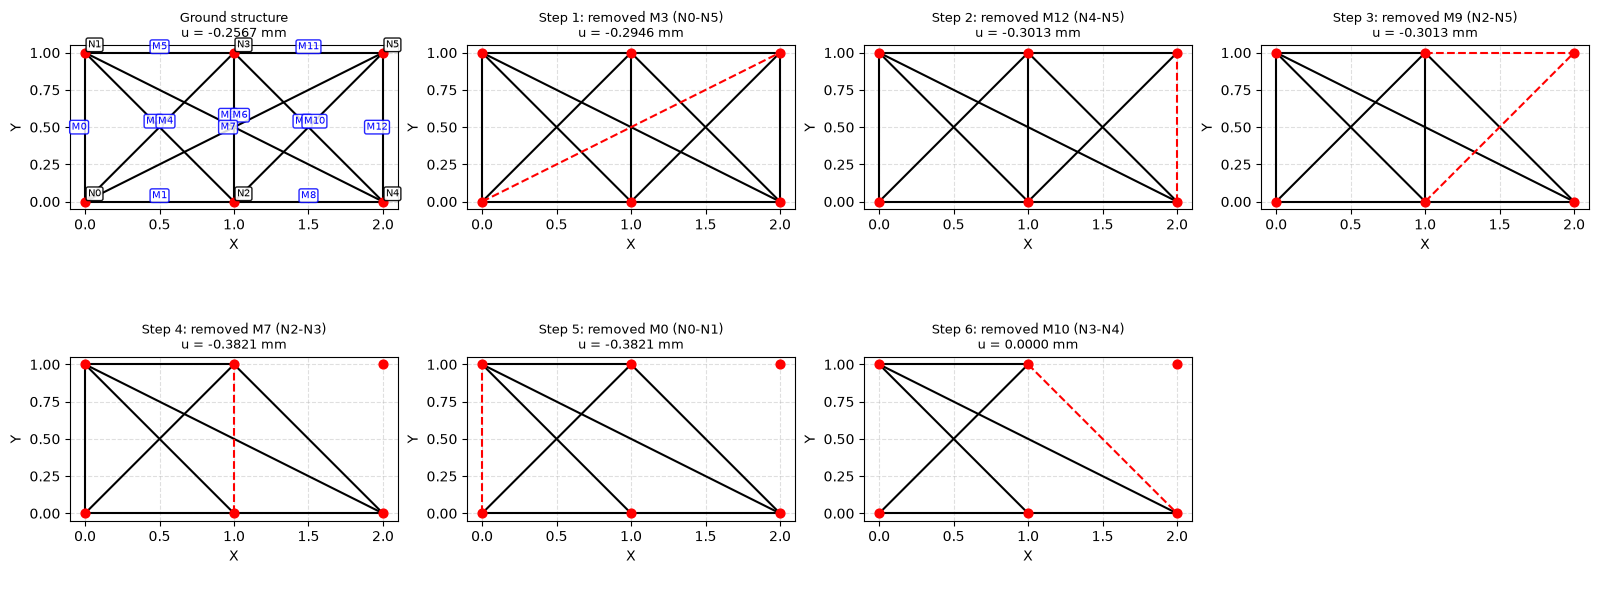

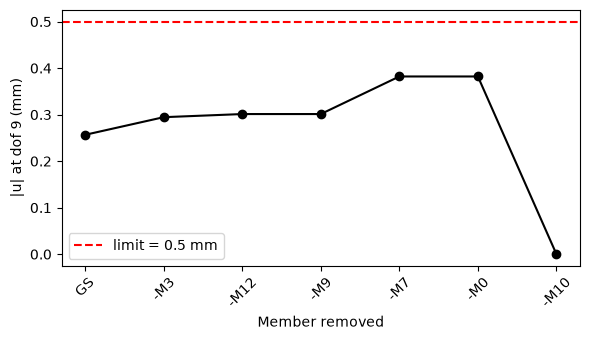


Exhaustive search: volume 0.03060 m3, members removed: ['M0', 'M2', 'M3', 'M9', 'M10', 'M11', 'M12']


In [39]:
env_TRE = TrussRemovalEnv(nodes, ground_structure_bars, dofs, A, E, ff, disp_dof=disp_dof, u_lim=u_lim)

# episodes: ~3000 for this 13-bar ground structure (~3 s); ~20000 for grid (3, 1), 22 bars (~25 s)
Q_TRE, rewards_TRE = train_TRE(env_TRE, episodes=3000, print_every=500)

plt.plot(np.convolve(rewards_TRE, np.ones(100) / 100, mode="valid"))
plt.xlabel("Episode")
plt.ylabel("Reward (fraction of volume saved), moving average of 100")
plt.show()

history_TRE = run_trained_TRE_agent(env_TRE, Q_TRE)

if env_TRE.n_bars <= 16:
    V_ex, s_ex = exhaustive_best(env_TRE)
    print(f"\nExhaustive search: volume {V_ex:.5f} m3, members removed: {[f'M{k}' for k in np.where(s_ex == 0)[0]]}")